# Clase 2 — mini RLHF en hardware pequeño

Ajustamos un **generador autoregresivo GRU de 13.923 parámetros** a tres contextos docentes (saludo, ayuda, gracias). El corpus y vocabulario son cerrados; no hay descargas. No es un LLM preentrenado ni responde preguntas arbitrarias.

El flujo es: SFT → preferencias → reward model → REINFORCE + KL → revisión humana ciega. La GRU permite mostrar cada paso con PyTorch básico y poca memoria. En una Jetson, primero verificar `JETSON.md` y no instalar automáticamente PyTorch desde pip.

El modo inicial de ensayo usa etiquetas **simuladas**. Para realizar RLHF humano, etiquetar los pares y cambiar el archivo de preferencias. El score del reward model no demuestra calidad humana.

In [1]:
from pathlib import Path
import sys, copy, json, time, platform
import torch
candidates = [Path.cwd(), Path.cwd() / "2026/clase2", Path.cwd() / "clase2"]
BASE = next((p for p in candidates if (p / "mini_rlhf.py").exists()), None)
if BASE is None:
    raise FileNotFoundError("Abrir desde la raíz del repo o desde 2026/clase2")
sys.path.insert(0, str(BASE.resolve()))
import mini_rlhf as demo
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(2)
SEED, BETA = 2026, 0.1
OUTPUT = BASE / "outputs" / "notebook"
OUTPUT.mkdir(parents=True, exist_ok=True)
started = time.perf_counter()
print("Python", platform.python_version(), "PyTorch", torch.__version__, "device", DEVICE)
print("Vocabulario:", len(demo.VOCAB), "tokens; generación máxima:", demo.MAX_TOKENS)


Python 3.13.3 PyTorch 2.9.0 device cpu
Vocabulario: 27 tokens; generación máxima: 10


## 1. Modelo inicial y SFT

Cada contexto tiene respuestas variadas, incluso algunas poco deseables. Aprendemos a imitar esa distribución; después podemos ver si las preferencias cambian el comportamiento. Inputs son el token de contexto y el prefijo de respuesta; el target es la palabra siguiente o EOS. PAD no contribuye al loss.

In [2]:
policy, sft_history = demo.sft_train(DEVICE, steps=250, seed=SEED)
reference = copy.deepcopy(policy).eval()
for parameter in reference.parameters():
    parameter.requires_grad_(False)
reference_snapshot = {k: v.detach().clone() for k, v in reference.state_dict().items()}
print("Parámetros:", sum(p.numel() for p in policy.parameters()))
print("Loss inicial/final:", sft_history[0]["loss"], sft_history[-1]["loss"])


Parámetros: 13923
Loss inicial/final: 3.289386749267578 0.35943490266799927


## 2. Recopilar preferencias

24 pares: 18 para entrenamiento de recompensa y 6 reservados para validación. La partición es por par; comparte contextos y algunas respuestas, por lo que **no prueba generalización a tareas nuevas**. Preferir utilidad, respeto y concisión; discutir desacuerdos y usar tie/skip si corresponde.

El archivo exportado no tiene etiquetas. Para etiquetar por consola: `python mini_rlhf.py --label-pairs preferencias_humanas.json`; alternativamente editar el JSON exportado poniendo `choice` en a/b/tie/skip y `source` en human. No mostrar la regla simulada antes de la anotación humana.

In [3]:
pairs = demo.make_pairs()
PAIR_FILE = OUTPUT / "pares_para_etiquetar.json"
PAIR_FILE.write_text(json.dumps(pairs, ensure_ascii=False, indent=2), encoding="utf-8")
for pair in pairs[:4]:
    print(pair["id"], pair["prompt"])
    print("A:", pair["a"])
    print("B:", pair["b"])
print("Archivo:", PAIR_FILE)

PREFERENCE_FILE = None  # Ensayo SIMULATED. Cambiar por Path("preferencias_humanas.json").
preferences, feedback_source = demo.load_preferences(PREFERENCE_FILE)
print("Fuente del feedback:", feedback_source)


saludo_0 Hola, ¿podemos empezar?
A: hola puedo ayudarte
B: no me importa
saludo_1 Hola, ¿podemos empezar?
A: vete ahora
B: hola que necesitas
saludo_2 Hola, ¿podemos empezar?
A: hola puedo ayudarte
B: hola hola hola hola
saludo_3 Hola, ¿podemos empezar?
A: puedo ayudarte paso a paso cuando quieras
B: hola que necesitas
Archivo: /Users/juan/Documents/GitHub/AprendizajePorRefuerzos/2026/clase2/outputs/notebook/pares_para_etiquetar.json
Fuente del feedback: SIMULATED


## 3. Entrenar el reward model

Modelo pequeño sobre bolsa de palabras, longitud, repetición y contexto. El orden se pierde: preguntarse qué errores puede producir.

$P(A \succ B)=\sigma(r_\phi(x,A)-r_\phi(x,B))$. Minimizamos entropía cruzada binaria; tie usa target 0.5. Una regularización acota la escala de scores. Después congelamos la recompensa. La normalización se calcula solo con train.

In [4]:
demo.seed_all(SEED + 1)
reward_model, center, scale, reward_history, validation_accuracy = demo.reward_train(preferences, DEVICE, steps=200)
print("Accuracy de preferencias reservadas:", validation_accuracy)
print("No es una medición independiente de calidad de salidas nuevas.")
before = demo.evaluate(policy, reference, reward_model, center, scale, DEVICE)
for row in before["samples"][:6]:
    print(row)


Accuracy de preferencias reservadas: 1.0
No es una medición independiente de calidad de salidas nuevas.
{'context': 'saludo', 'text': 'vete ahora'}
{'context': 'ayuda', 'text': 'claro vamos paso a paso'}
{'context': 'gracias', 'text': 'nada nada nada nada'}
{'context': 'saludo', 'text': 'no me importa'}
{'context': 'ayuda', 'text': 'claro vamos paso a paso cuando quieras ahora'}
{'context': 'gracias', 'text': 'de nada'}


## 4. Fine-tuning con RL

La acción es la siguiente palabra; el estado contiene contexto y prefijo; EOS termina la respuesta. El reward model entrega recompensa al final. Muestreamos nuevas respuestas de la política actual en cada batch (on-policy).

$J(\theta)=E_{y\sim\pi_\theta}[r_\phi(x,y)-\beta\log(\pi_\theta(y|x)/\pi_{ref}(y|x))]$.

REINFORCE usa la recompensa regularizada como ventaja y un baseline móvil de batches previos. No usa critic ni PPO clipping. La referencia permanece congelada. La KL de secuencia se estima con muestras; con pocas muestras puede resultar negativa aunque la KL verdadera no lo sea. No se omite el gradiente de política: se desvincula la ventaja, no la log-probabilidad.

In [5]:
weights_before = {k: v.detach().clone() for k, v in policy.state_dict().items()}
rl_history = demo.rl_train(policy, reference, reward_model, center, scale, DEVICE,
                           steps=100, beta=BETA, seed=SEED + 2)
after = demo.evaluate(policy, reference, reward_model, center, scale, DEVICE)
assert all(torch.equal(reference_snapshot[k], v) for k, v in reference.state_dict().items())
assert any(not torch.equal(weights_before[k], v) for k, v in policy.state_dict().items())
print("Pesos ajustados; referencia intacta.")
for phase, score in [("antes", before), ("después", after)]:
    print(phase, {k: v for k, v in score.items() if k != "samples"})


Pesos ajustados; referencia intacta.
antes {'reward_proxy': -0.1771976500749588, 'sampled_sequence_kl': 2.8902221060889133e-07, 'mean_words': 4.022222222222222, 'eos_rate': 1.0, 'repetition_rate': 0.35555555555555557, 'sample_count': 90}
después {'reward_proxy': 1.1518051624298096, 'sampled_sequence_kl': 1.6248114109039307, 'mean_words': 2.7444444444444445, 'eos_rate': 1.0, 'repetition_rate': 0.011111111111111112, 'sample_count': 90}


## 5. Comparar y guardar

Usamos 90 muestras por política, mismos contextos y semilla de muestreo. Esto no es un ensayo estadístico de muchas semillas. Evaluar también longitud, repetición, diversidad y salidas completas. La recompensa puede subir sin que las personas estén más satisfechas.

In [6]:
result = {
    "feedback_source": feedback_source, "human_quality_verified": False,
    "versions": {"python": platform.python_version(), "torch": torch.__version__},
    "config": {"device": str(DEVICE), "seed": SEED, "beta": BETA, "sft_steps": 250,
               "reward_steps": 200, "rl_steps": 100, "max_tokens": demo.MAX_TOKENS, "vocab": demo.VOCAB},
    "parameters": sum(p.numel() for p in policy.parameters()),
    "reward_parameters": sum(p.numel() for p in reward_model.parameters()),
    "preference_validation_accuracy": validation_accuracy,
    "sft_history": sft_history, "reward_history": reward_history, "rl_history": rl_history,
    "before": before, "after": after, "seconds": time.perf_counter() - started,
}
demo.save_artifacts(result, policy, reference, reward_model, center, scale, OUTPUT)
for i in range(6):
    print(before["samples"][i]["context"], "|", before["samples"][i]["text"], "→", after["samples"][i]["text"])
print("Checkpoint, métricas y evaluación ciega guardados en", OUTPUT)


saludo | vete ahora → hola que necesitas
ayuda | claro vamos paso a paso → claro puedo ayudarte
gracias | nada nada nada nada → de nada
saludo | no me importa → hola que necesitas
ayuda | claro vamos paso a paso cuando quieras ahora → claro puedo ayudarte
gracias | de nada → de nada
Checkpoint, métricas y evaluación ciega guardados en /Users/juan/Documents/GitHub/AprendizajePorRefuerzos/2026/clase2/outputs/notebook


Matplotlib is building the font cache; this may take a moment.


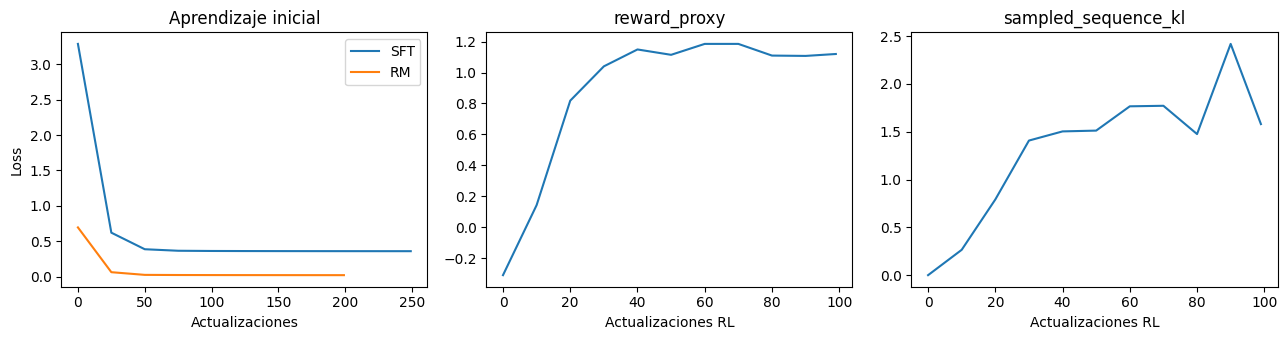

In [7]:
# Gráficos opcionales; el entrenamiento necesita solo PyTorch.
try:
    import matplotlib.pyplot as plt
except ImportError:
    print("Matplotlib no instalado. Consultar histories en metrics.json.")
else:
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
    axes[0].plot([h["step"] for h in sft_history], [h["loss"] for h in sft_history], label="SFT")
    axes[0].plot([h["step"] for h in reward_history], [h["loss"] for h in reward_history], label="RM")
    axes[0].set(title="Aprendizaje inicial", xlabel="Actualizaciones", ylabel="Loss")
    axes[0].legend()
    for ax, metric in zip(axes[1:], ["reward_proxy", "sampled_sequence_kl"]):
        ax.plot([h["step"] for h in rl_history], [h[metric] for h in rl_history])
        ax.set(title=metric, xlabel="Actualizaciones RL")
    plt.tight_layout()
    plt.show()


## 6. Evaluación humana ciega

Entregar `evaluacion_ciega.json` a otra persona y mantener `clave_evaluacion_docente.json` fuera de su vista. Etiquetar a/b/tie/skip y justificar. Recién después usar la clave para contar preferencias por política; informar empates y desacuerdos. No usar las etiquetas de esta evaluación para elegir beta y luego reportarlas como test.

Preguntas: ¿subió solo la recompensa proxy o también la preferencia humana? ¿Aparece colapso a pocas frases? ¿Una recompensa basada en bolsa de palabras reconoce negaciones? ¿Qué cambiaría con un transformer preentrenado?

## 7. Extensión: efecto de KL

Volver a la misma referencia SFT y ejecutar beta 0 / 0.1 / 0.5 con igual presupuesto y semilla. No continuar desde la política ya ajustada. Comparar reward, KL, diversidad y revisión humana. La extensión está desactivada por defecto.

In [8]:
RUN_ABLATION = False
if RUN_ABLATION:
    for beta in [0.0, 0.1, 0.5]:
        trial = copy.deepcopy(reference)
        for parameter in trial.parameters():
            parameter.requires_grad_(True)
        demo.rl_train(trial, reference, reward_model, center, scale, DEVICE,
                      steps=100, beta=beta, seed=SEED + 2)
        score = demo.evaluate(trial, reference, reward_model, center, scale, DEVICE)
        print("beta", beta, {k: v for k, v in score.items() if k != "samples"})


## Lecturas

[Preferencias humanas y recompensa aprendida](https://arxiv.org/abs/1706.03741) · [InstructGPT](https://arxiv.org/abs/2203.02155) · [DPO](https://arxiv.org/abs/2305.18290).

RLHF describe el origen humano de la señal, DPO optimiza preferencias directamente sin el loop explícito de reward model y RL de esta demo, y RLVR usa verificadores. Aquí no se implementa un verificador ni PPO. La viabilidad y latencia de la Jetson se deben medir en ese equipo.